# Assignment 1: Plotting a Normal Distribution Curve in Python

**Learning outcomes**
- Understand the properties and significance of the normal distribution.
- Use Python to generate and visualise statistical data.
- Analyse data using the mean and standard deviation.
- Think critically about how distributions affect decisions.

**Case study: Quality control in manufacturing.** A machine cuts metal bolts to a target diameter of 10.00 mm. Diameters vary slightly from bolt to bolt, and we model that variation as normal. Bolts outside the specification limits are defective.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)


## 1. The normal curve and its properties

The normal distribution is described by two parameters: the mean (μ), which sets the centre, and the standard deviation (σ), which sets the spread. About 68% of values fall within ±1σ, 95% within ±2σ and 99.7% within ±3σ (the empirical rule).

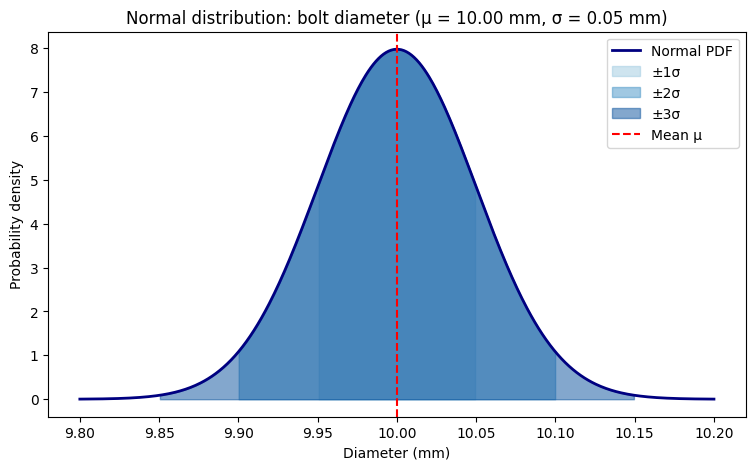

P(within ±1σ) = 0.6827
P(within ±2σ) = 0.9545
P(within ±3σ) = 0.9973


In [2]:
mu, sigma = 10.00, 0.05          # target diameter and process standard deviation (mm)
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
pdf = stats.norm.pdf(x, mu, sigma)

fig, ax = plt.subplots()
ax.plot(x, pdf, color="navy", lw=2, label="Normal PDF")
colours = ["#9ecae1", "#4292c6", "#08519c"]
for k, c in zip([1, 2, 3], colours):
    m = (x >= mu - k * sigma) & (x <= mu + k * sigma)
    ax.fill_between(x[m], pdf[m], color=c, alpha=0.5, label=f"±{k}σ")
ax.axvline(mu, color="red", ls="--", label="Mean μ")
ax.set_title("Normal distribution: bolt diameter (μ = 10.00 mm, σ = 0.05 mm)")
ax.set_xlabel("Diameter (mm)")
ax.set_ylabel("Probability density")
ax.legend()
plt.show()

# Check the empirical rule with scipy
for k in [1, 2, 3]:
    p = stats.norm.cdf(mu + k * sigma, mu, sigma) - stats.norm.cdf(mu - k * sigma, mu, sigma)
    print(f"P(within ±{k}σ) = {p:.4f}")


## 2. Simulated production sample: mean and standard deviation

We simulate 1,000 bolts from the process and summarise them with descriptive statistics. `ddof=1` gives the sample standard deviation.

,count,mean,std (sample),min,median,max
0,1000,10.001,0.049,9.8379,10.0013,10.1926


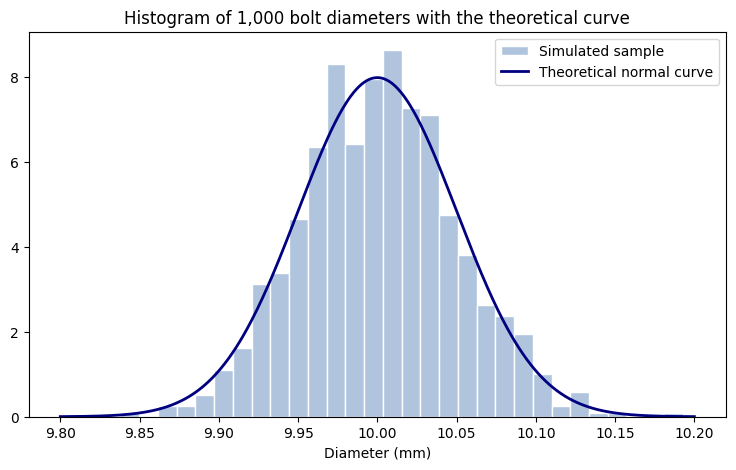

In [3]:
sample = np.random.normal(mu, sigma, 1000)
s = pd.Series(sample, name="diameter_mm")

summary = pd.DataFrame({
    "count": [s.count()],
    "mean": [s.mean()],
    "std (sample)": [s.std(ddof=1)],
    "min": [s.min()],
    "median": [s.median()],
    "max": [s.max()],
}).round(4)
display(summary)

fig, ax = plt.subplots()
ax.hist(sample, bins=30, density=True, color="lightsteelblue", edgecolor="white", label="Simulated sample")
ax.plot(x, pdf, color="navy", lw=2, label="Theoretical normal curve")
ax.set_title("Histogram of 1,000 bolt diameters with the theoretical curve")
ax.set_xlabel("Diameter (mm)")
ax.legend()
plt.show()


## 3. Quality control: defect rate and process capability

Specification limits: **LSL = 9.85 mm** and **USL = 10.15 mm**.
- The defect rate is the probability of falling outside those limits.
- The capability index **Cp = (USL − LSL) / (6σ)** compares the allowed spread with the natural spread of the process. A value of at least 1.33 is usually considered capable.

In [4]:
LSL, USL = 9.85, 10.15

def defect_rate(mean, sd):
    below = stats.norm.cdf(LSL, mean, sd)
    above = 1 - stats.norm.cdf(USL, mean, sd)
    return below + above

cp = (USL - LSL) / (6 * sigma)
print(f"Defect rate (in control, μ = 10.00): {defect_rate(10.00, sigma):.4%}")
print(f"Capability index Cp: {cp:.2f}")
print(f"Defects per million opportunities: {defect_rate(10.00, sigma) * 1e6:,.0f}")


Defect rate (in control, μ = 10.00): 0.2700%
Capability index Cp: 1.00
Defects per million opportunities: 2,700


## 4. Effect of a process shift on decisions

Machines drift over time. If the mean moves from 10.00 mm to 10.03 mm, the defect rate rises sharply even though the spread has not changed. This is why a process should be monitored, not only tested once.

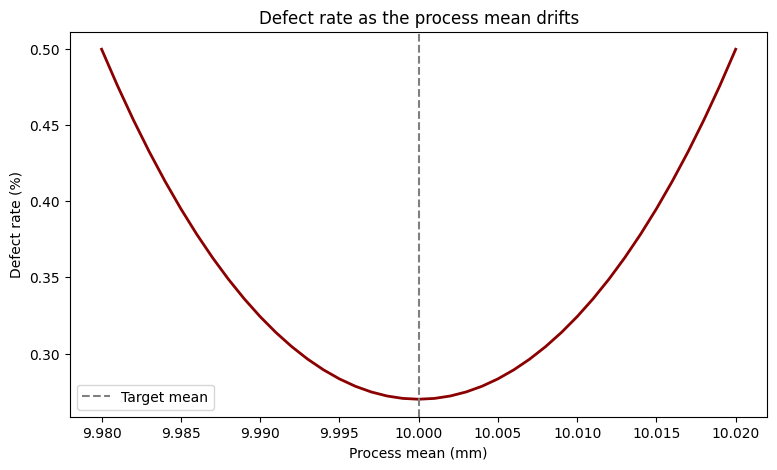

Mean 10.00 mm -> defect rate 0.270%
Mean 10.01 mm -> defect rate 0.324%
Mean 10.02 mm -> defect rate 0.500%


In [5]:
shifts = np.linspace(9.98, 10.02, 41)
rates = [defect_rate(m, sigma) for m in shifts]

fig, ax = plt.subplots()
ax.plot(shifts, np.array(rates) * 100, color="darkred", lw=2)
ax.axvline(10.00, color="grey", ls="--", label="Target mean")
ax.set_title("Defect rate as the process mean drifts")
ax.set_xlabel("Process mean (mm)")
ax.set_ylabel("Defect rate (%)")
ax.legend()
plt.show()

for m in [10.00, 10.01, 10.02]:
    print(f"Mean {m:.2f} mm -> defect rate {defect_rate(m, sigma):.3%}")


## 5. Applying the same idea to other cases

- **Student test scores:** if scores are roughly normal, a z-score tells you how far a student is from the class average in standard deviations.
- **Stock daily returns:** returns are often modelled as normal, but real markets have fatter tails, so extreme losses can be more common than the normal curve predicts.
- **Hospital wait times:** wait times are usually right-skewed, so a normal model can understate long waits. Check the histogram before relying on the mean.

**Critical thinking:** A normal model is only as good as the fit. Always plot the data first and compare it with the theoretical curve before making a decision based on it.

In [6]:
# Example: z-scores for student test scores (simulated, mean 70, sd 8)
scores = pd.Series(np.random.normal(70, 8, 40).round(1), name="score")
z = (scores - scores.mean()) / scores.std(ddof=1)
result = pd.DataFrame({"score": scores, "z_score": z.round(2)})
display(result.sort_values("z_score", ascending=False).head(5))
print("Share of students more than 1.5 standard deviations above the mean:",
      f"{(z > 1.5).mean():.1%}")


,score,z_score
23,87.1,1.97
12,86.6,1.90
14,83.9,1.54
24,83.8,1.53
35,82.6,1.37


Share of students more than 1.5 standard deviations above the mean: 10.0%
